# A02-DB — DBSCAN trên RFM (RFM thô → StandardScaler (không PCA))

Thí nghiệm **A02-DB** (người chạy: Thuận, hạn nội bộ 17/11/2026) theo chiến lược model. So với A01, **chỉ bỏ PCA**. Quy trình: làm sạch → RFM → RFM thô → StandardScaler (không PCA) → DBSCAN.

## Params

In [ ]:
FEATURES = ["Recency", "Frequency", "Monetary"]
RANDOM_STATE = 42
MIN_SAMPLES_GRID = [4, 6, 8, 10, 15, 20]
EPS_GRID = [0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0, 1.5, 2.0]                 
MAX_NOISE = 0.05            
MIN_CLUSTERS = 2           

## Import thư viện và đọc dữ liệu

In [ ]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PowerTransformer, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)

def find(rel):
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())


DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"})
X = df[FEATURES].copy()
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 3)


,Recency,Frequency,Monetary
count,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95
std,99.98,7.64,8441.89
min,1.00,1.00,2.90
25%,18.00,1.00,301.52
50%,51.00,2.00,657.90
75%,143.00,5.00,1624.10
max,374.00,206.00,278748.02


**Nhận xét:** 4,327 khách, dùng chung file feature của nhóm. Monetary lệch phải rất mạnh (trung vị 657.9, max 278,748) nên tiền xử lý ảnh hưởng nhiều đến kết quả.

## Tiền xử lý

RFM thô → StandardScaler (không PCA).

In [3]:
prep = Pipeline([
    ("scaler", StandardScaler()),
])
Z = prep.fit_transform(X.values)
print("Kích thước đầu vào mô hình:", Z.shape)

Kích thước đầu vào mô hình: (4327, 3)


## Quét lưới eps × min_samples

In [4]:
rows = []
for ms in MIN_SAMPLES_GRID:
    for eps in EPS_GRID:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z)
        core = lab != -1
        sizes = np.bincount(lab[core]) if core.any() else np.array([0])
        ncl = len(sizes) if core.any() else 0
        ok = ncl >= 2
        rows.append({"min_samples": ms, "eps": eps, "n_clusters": ncl, "noise_pct": round(100 * (~core).mean(), 2),
                     "largest_pct": round(100 * sizes.max() / len(lab), 2), "smallest": int(sizes.min()),
                     "silhouette": silhouette_score(Z[core], lab[core]) if ok else np.nan,
                     "dbi": davies_bouldin_score(Z[core], lab[core]) if ok else np.nan})
res = pd.DataFrame(rows)
elig = res[(res["n_clusters"] >= MIN_CLUSTERS) & (res["noise_pct"] <= 100 * MAX_NOISE)]
best = elig.sort_values(["silhouette", "noise_pct"], ascending=[False, True]).iloc[0]
print(f"Đủ điều kiện: {len(elig)}/{len(res)} cấu hình")
print(f"Chọn eps={best['eps']}, min_samples={int(best['min_samples'])}: {int(best['n_clusters'])} cụm, nhiễu {best['noise_pct']}%, "
      f"Silhouette (không tính nhiễu)={best['silhouette']:.4f}, DBI={best['dbi']:.4f}")
elig.sort_values("silhouette", ascending=False).head(8).round(4)

Đủ điều kiện: 7/54 cấu hình
Chọn eps=1.5, min_samples=4: 3 cụm, nhiễu 0.42%, Silhouette (không tính nhiễu)=0.8177, DBI=0.4046


,min_samples,eps,n_clusters,noise_pct,largest_pct,smallest,silhouette,dbi
7,4,1.5,3,0.42,99.40,4,0.8177,0.4046
2,4,0.3,2,2.29,97.53,8,0.6668,0.3041
11,6,0.3,2,2.43,97.43,6,0.6596,0.2909
29,10,0.3,2,2.96,96.81,10,0.5761,0.3746
1,4,0.2,5,3.35,95.98,4,0.3314,0.5449
19,8,0.2,2,4.41,95.40,8,0.3200,0.5991
10,6,0.2,3,3.95,95.68,6,0.3167,0.5237


**Nhận xét:** 3 cụm, nhiễu 0.42%, cụm lớn nhất chiếm 99.4% khách, cụm nhỏ nhất 4 khách. Silhouette/DBI chỉ tính trên khách không bị coi là nhiễu.

## Fit DBSCAN cuối và đồ thị k-distance

Số khách mỗi cụm (-1 = nhiễu): {-1: 18, 0: 4301, 1: 4, 2: 4}


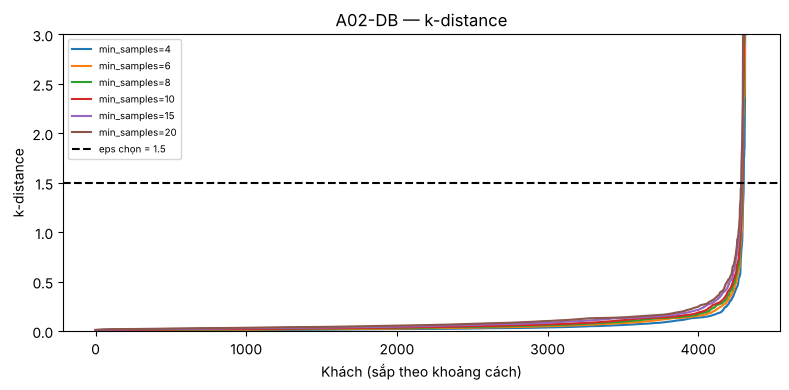

In [5]:
dbs = DBSCAN(eps=float(best["eps"]), min_samples=int(best["min_samples"])).fit(Z)
labels = dbs.labels_
core = labels != -1
print("Số khách mỗi cụm (-1 = nhiễu):", {int(k): int(v) for k, v in zip(*np.unique(labels, return_counts=True))})

# Đồ thị k-distance để đối chiếu với eps đã chọn
fig, ax = plt.subplots(figsize=(8, 4))
for ms in MIN_SAMPLES_GRID:
    d = NearestNeighbors(n_neighbors=ms).fit(Z).kneighbors(Z)[0][:, -1]
    ax.plot(np.sort(d), label=f"min_samples={ms}")
ax.axhline(float(best["eps"]), color="black", ls="--", label=f"eps chọn = {best['eps']}")
ax.set_ylim(0, 3); ax.set_xlabel("Khách (sắp theo khoảng cách)"); ax.set_ylabel("k-distance"); ax.legend(fontsize=7)
ax.set_title("A02-DB — k-distance"); plt.tight_layout(); plt.savefig(FIG / "k_distance.png", dpi=150); plt.show()

## Hồ sơ cụm (trên RFM gốc, trung vị)

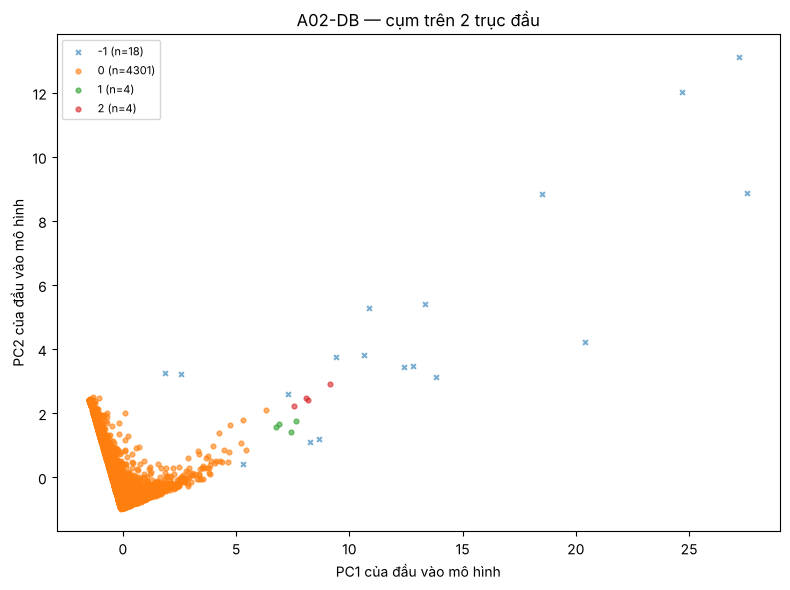

,customers,Recency,Frequency,Monetary,customer_share_pct,Monetary_share_pct
cluster,,,,,,
-1,18,3.0,61.0,63643.2,0.4,19.2
0,4301,52.0,2.0,654.7,99.4,76.5
1,4,3.0,54.0,35907.5,0.1,1.6
2,4,4.0,46.0,56282.3,0.1,2.7


In [6]:
prof = X.assign(cluster=labels).groupby("cluster").agg(
    customers=("Monetary", "size"), Recency=("Recency", "median"), Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"), Monetary_sum=("Monetary", "sum"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof = prof.drop(columns="Monetary_sum").round(1)

coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Z) if Z.shape[1] > 2 else Z
fig, ax = plt.subplots(figsize=(8, 6))
for c in sorted(np.unique(labels)):
    m = labels == c
    ax.scatter(coords[m, 0], coords[m, 1], s=12, alpha=0.6, marker="x" if c == -1 else "o", label=f"{c} (n={m.sum()})")
ax.set_xlabel("PC1 của đầu vào mô hình"); ax.set_ylabel("PC2 của đầu vào mô hình"); ax.legend(fontsize=8)
ax.set_title("A02-DB — cụm trên 2 trục đầu")
plt.tight_layout(); plt.savefig(FIG / "dbscan_clusters_pca.png", dpi=150); plt.show()
prof

**Nhận xét:** Cụm 2 có Monetary trung vị cao nhất (56,282), gồm 4 khách (0.1%) nhưng chiếm 2.7% tổng Monetary. Cụm 0 đông nhất (99.4% khách, Recency trung vị 52 ngày). Nhóm nhiễu (-1) có 18 khách, chiếm 19.2% tổng Monetary. Một cụm chiếm ≥ 90% khách, nên kết quả chỉ phân biệt nhóm ngoại lai với số đông, chưa phải phân khúc khách hàng chi tiết.

## Đối chiếu với A01 (cùng tham số model)

In [ ]:

prep_parent = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.9, svd_solver="full", random_state=RANDOM_STATE)),
])
Zp = prep_parent.fit_transform(X.values)
lp = DBSCAN(eps=float(best["eps"]), min_samples=int(best["min_samples"])).fit_predict(Zp)
ari_parent = adjusted_rand_score(labels, lp)
same_dims = Zp.shape[1] == Z.shape[1]
same_geometry = same_dims and np.allclose(np.linalg.norm(Z[:300, None] - Z[None, :300], axis=2),
                                          np.linalg.norm(Zp[:300, None] - Zp[None, :300], axis=2), atol=1e-8)
print(f"A02: {Z.shape[1]} chiều | A01: {Zp.shape[1]} chiều")
print(f"ARI giữa nhãn A02 và nhãn A01 (cùng tham số): {ari_parent:.4f}")
print("Cùng hình học khoảng cách:", same_geometry)

A02: 3 chiều | A01: 3 chiều
ARI giữa nhãn A02 và nhãn A01 (cùng tham số): 1.0000
Cùng hình học khoảng cách: True


**Nhận xét:** ARI giữa A02 và A01 (cùng tham số) = 1.0000; số chiều đầu vào 3 so với 3. Hình học khoảng cách giống hệt và nhãn trùng 100%, nên **A02 tương đương A01** (chỉ là phép xoay PCA, không đổi kết quả).

## Lưu kết quả

In [9]:
res.to_csv(OUT / "dbscan_a02_grid.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "dbscan_a02_labels.csv", index=False)
params = {"experiment": "A02-DB", "features": FEATURES, "transform": None,
          "scaler": "StandardScaler", "pca": None,
          "n_components": int(Z.shape[1]), "n_customers": int(len(X)),
          "eps": float(best["eps"]), "min_samples": int(best["min_samples"]), "n_clusters": int(best["n_clusters"]),
          "noise_pct": float(best["noise_pct"]), "largest_pct": float(best["largest_pct"]), "smallest": int(best["smallest"]),
          "silhouette_non_noise": float(best["silhouette"]), "dbi_non_noise": float(best["dbi"]),
          "ari_vs_parent_fixed_params": {"parent": "A01", "ari": float(ari_parent)}}
json.dump(params, open(OUT / "dbscan_a02_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['dbscan_a02_grid.csv', 'dbscan_a02_labels.csv', 'dbscan_a02_params.json']


**Lưu ý:** DBSCAN không có `predict` cho khách mới, `labels_` chỉ áp dụng đúng 4.327 khách và đúng thứ tự khi fit, nên không lưu file model.

**Kết luận A02-DB:** DBSCAN eps=1.5, min_samples=4: 3 cụm, nhiễu 0.42%. ARI với A01 (cùng tham số) = 1.0000. Silhouette giữa các cấu hình khác không gian đầu vào (số chiều, scaler) không so sánh trực tiếp được; dùng ARI và hồ sơ cụm trên RFM gốc để so sánh.